# Retinal Disease Detection Using Deep Learning on OCT Images
## Step 3: Neural Network Fundamentals (NumPy)

**Goals**
- Implement a basic perceptron and a multi-layer neural network using only NumPy
- Experiment with ReLU, Sigmoid and Tanh activation functions
- Understand forward propagation, loss calculation and backpropagation
- Explore optimization techniques (SGD, momentum, RMSprop, Adam, learning rate, batch size, regularization) to see how a model learns



In [1]:
# Run once if the packages are missing (no PyTorch needed in this step)
%pip install -q numpy pandas matplotlib seaborn pillow datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

In [3]:
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from datasets import load_dataset

SEED = 42
if os.path.exists("preprocessing_config.json"):          # written at the end of Step 2
    with open("preprocessing_config.json") as f:
        SEED = json.load(f).get("seed", SEED)

random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

sns.set_style("whitegrid")
print("numpy", np.__version__, "| seed", SEED)

numpy 2.3.5 | seed 42


## 3.1 Load a small, flattened version of the OCT data
A fully connected network treats every pixel as an independent input, so we keep the input small: grey-level, **32 x 32 = 1,024 features**, scaled to 0-1 and then standardized with the training mean and std (like the normalization in Step 2).

We draw a **balanced** random subset (600 scans per class) from the training split, cut 20% of it as validation (stratified), and use the official test split untouched.

In [4]:
dataset = load_dataset("zacharielegault/Kermany2017-OCT")
train_data, test_data = dataset["train"], dataset["test"]
class_names = train_data.features["label"].names
n_classes = len(class_names)

train_labels_all = np.array(train_data["label"])
test_labels_all = np.array(test_data["label"])
print("Classes:", class_names)

Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


In [5]:
IMG = 32                    # images are shrunk to IMG x IMG
PER_CLASS_TRAIN = 600       # scans per class drawn from the training split
VAL_FRACTION = 0.20

def to_vector(img):
    small = img.convert("L").resize((IMG, IMG), Image.BILINEAR)
    return np.asarray(small, dtype=np.float32).ravel() / 255.0

def load_subset(ds, labels, per_class):
    picks = []
    for c in range(n_classes):
        pool = np.where(labels == c)[0]
        picks.append(rng.choice(pool, min(per_class, len(pool)), replace=False))
    idx = rng.permutation(np.concatenate(picks))
    X = np.stack([to_vector(ds[int(i)]["image"]) for i in idx])
    return X, labels[idx]

def stratified_split(y, frac, rng):
    val_idx = []
    for c in np.unique(y):
        ids = rng.permutation(np.where(y == c)[0])
        val_idx.append(ids[: int(len(ids) * frac)])
    val_idx = np.concatenate(val_idx)
    mask = np.zeros(len(y), dtype=bool)
    mask[val_idx] = True
    return np.where(~mask)[0], np.where(mask)[0]

t0 = time.time()
X_all, y_all = load_subset(train_data, train_labels_all, PER_CLASS_TRAIN)
X_test, y_test = load_subset(test_data, test_labels_all, 10_000)     # whole test split
tr_idx, va_idx = stratified_split(y_all, VAL_FRACTION, rng)
X_train, y_train = X_all[tr_idx], y_all[tr_idx]
X_val, y_val = X_all[va_idx], y_all[va_idx]

# standardize with TRAIN statistics only (one mean / std for all pixels)
pix_mean, pix_std = float(X_train.mean()), float(X_train.std())
X_train, X_val, X_test = [((a - pix_mean) / pix_std).astype(np.float32) for a in (X_train, X_val, X_test)]

print(f"Loaded in {time.time() - t0:.0f}s")
print(f"train {X_train.shape} | val {X_val.shape} | test {X_test.shape}")
print(f"pixel mean {pix_mean:.4f}, std {pix_std:.4f}")
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}", {class_names[k]: int(v) for k, v in zip(*np.unique(y, return_counts=True))})

Loaded in 18s
train (1920, 1024) | val (480, 1024) | test (1000, 1024)
pixel mean 0.1918, std 0.2002
train {'CNV': 480, 'DME': 480, 'DRUSEN': 480, 'NORMAL': 480}
val   {'CNV': 120, 'DME': 120, 'DRUSEN': 120, 'NORMAL': 120}
test  {'CNV': 250, 'DME': 250, 'DRUSEN': 250, 'NORMAL': 250}


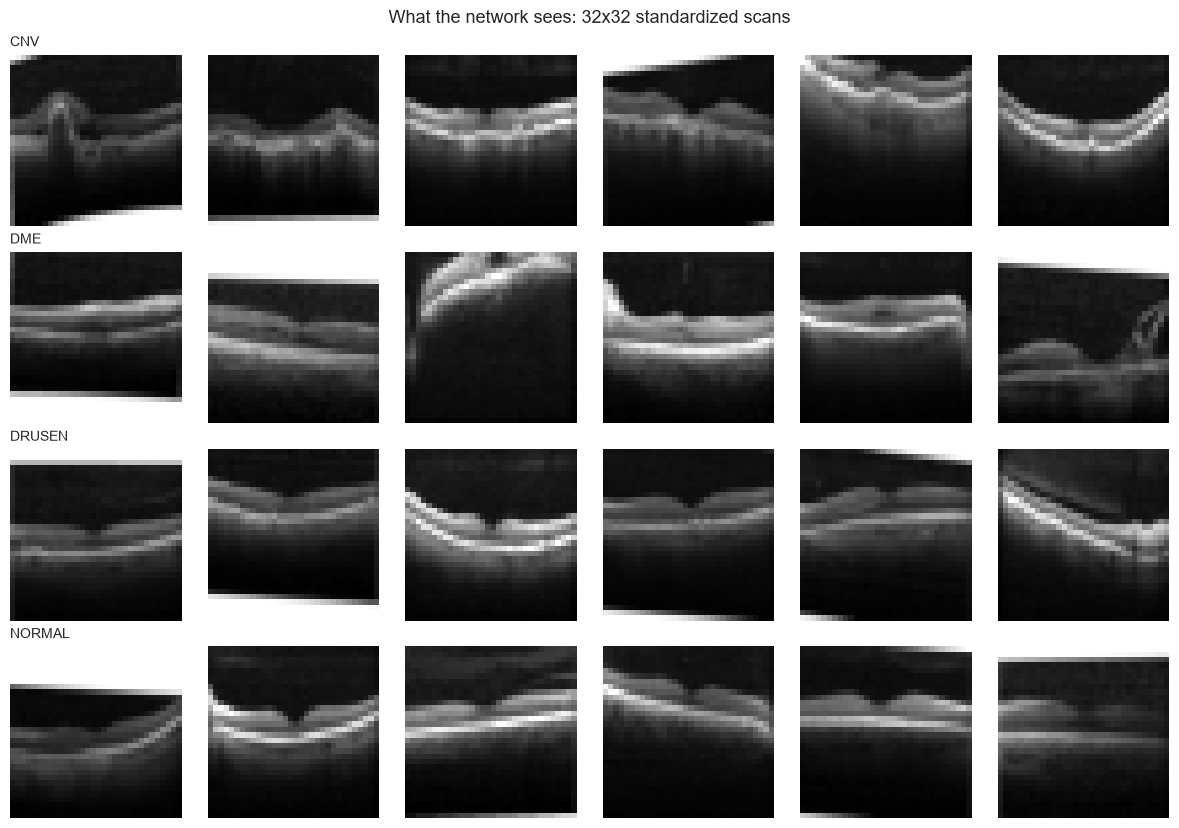

In [6]:
fig, axes = plt.subplots(n_classes, 6, figsize=(12, 2.1 * n_classes))
for r in range(n_classes):
    ids = np.where(y_train == r)[0][:6]
    for ax, i in zip(axes[r], ids):
        ax.imshow(X_train[i].reshape(IMG, IMG), cmap="gray")
        ax.axis("off")
    axes[r, 0].set_title(class_names[r], loc="left", fontsize=10)
plt.suptitle(f"What the network sees: {IMG}x{IMG} standardized scans", fontsize=13)
plt.tight_layout()
plt.show()

## 3.2 A basic perceptron
A perceptron is a single artificial neuron:

$$\hat y = \begin{cases}1 & \text{if } w\cdot x + b \ge 0\\ 0 & \text{otherwise}\end{cases}$$

**Learning rule:** for each sample, nudge the weights by `lr * (y - y_hat) * x`. A correct prediction changes nothing; a wrong one moves the decision line toward the right side. If the classes are linearly separable, this is guaranteed to converge.

In [7]:
class Perceptron:
    def __init__(self, n_features, lr=0.1):
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.lr = lr
        self.errors_ = []

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)

    def fit(self, X, y, epochs=20):
        self.errors_ = []
        for _ in range(epochs):
            errors = 0
            for xi, yi in zip(X, y):
                update = self.lr * (yi - int(xi @ self.w + self.b >= 0))
                self.w += update * xi
                self.b += update
                errors += int(update != 0)
            self.errors_.append(errors)
            if errors == 0:            # every sample correct: converged
                break
        return self

### Logic gates: what one neuron can and cannot learn

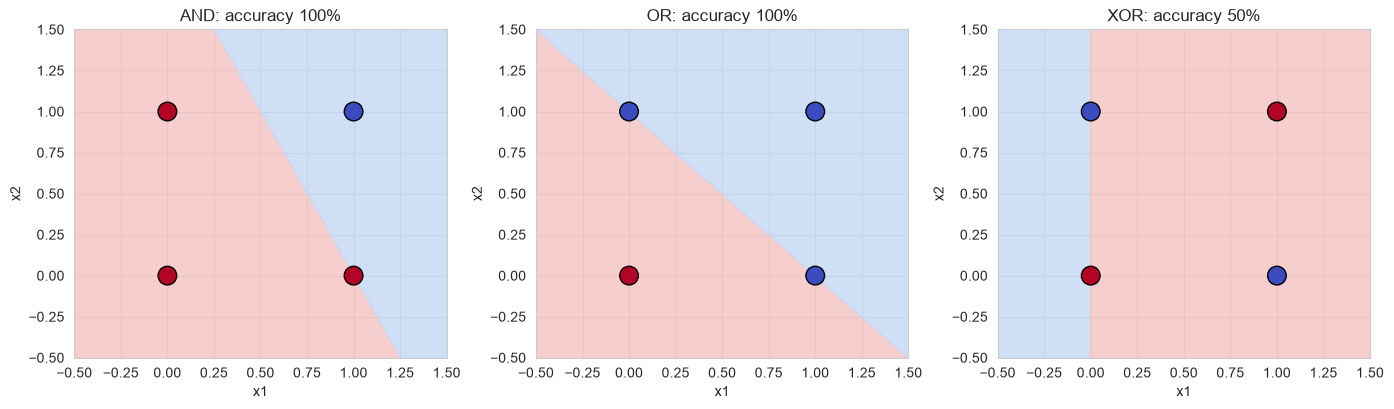

,gate,epochs run,converged,accuracy
0,AND,4,True,1.0
1,OR,4,True,1.0
2,XOR,50,False,0.5


In [8]:
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
gates = {"AND": np.array([0, 0, 0, 1]), "OR": np.array([0, 1, 1, 1]), "XOR": np.array([0, 1, 1, 0])}

gx, gy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
rows = []
for ax, (name, y_g) in zip(axes, gates.items()):
    p = Perceptron(2, lr=0.1).fit(X_gate, y_g, epochs=50)
    acc = (p.predict(X_gate) == y_g).mean()
    rows.append({"gate": name, "epochs run": len(p.errors_), "converged": p.errors_[-1] == 0, "accuracy": acc})
    ax.contourf(gx, gy, p.predict(grid).reshape(gx.shape), levels=[-0.5, 0.5, 1.5], colors=["#f4c2c2", "#c2d8f4"], alpha=0.8)
    ax.scatter(X_gate[:, 0], X_gate[:, 1], c=y_g, cmap="coolwarm_r", s=180, edgecolor="k", zorder=3)
    ax.set_title(f"{name}: accuracy {acc:.0%}")
    ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

**What to look for:** AND and OR are separated by a single straight line, so the perceptron reaches 100%. **XOR cannot be separated by any single line**, so it never converges. This is the classic reason we stack neurons into hidden layers (Section 3.4).

### The perceptron on real OCT data (NORMAL vs CNV)
Same learner, now with 1,024 pixel inputs and two classes. If the two classes were linearly separable in pixel space, the error count would drop to zero.

Perceptron NORMAL vs CNV | train acc 0.697 | val acc 0.637


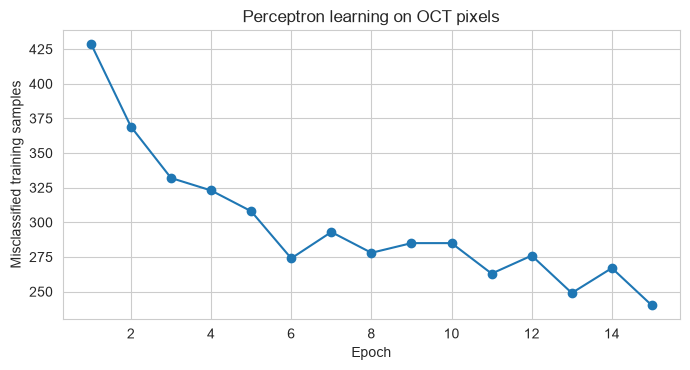

In [9]:
cnv, normal = class_names.index("CNV"), class_names.index("NORMAL")

def binary_subset(X, y):
    m = np.isin(y, [cnv, normal])
    return X[m], (y[m] == cnv).astype(int)

Xb_tr, yb_tr = binary_subset(X_train, y_train)
Xb_va, yb_va = binary_subset(X_val, y_val)

perc = Perceptron(X_train.shape[1], lr=0.01).fit(Xb_tr, yb_tr, epochs=15)
print(f"Perceptron NORMAL vs CNV | train acc {(perc.predict(Xb_tr) == yb_tr).mean():.3f} "
      f"| val acc {(perc.predict(Xb_va) == yb_va).mean():.3f}")

plt.figure(figsize=(7, 3.8))
plt.plot(range(1, len(perc.errors_) + 1), perc.errors_, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Misclassified training samples")
plt.title("Perceptron learning on OCT pixels")
plt.tight_layout()
plt.show()

**What to look for:** the error count rarely reaches zero and bounces around, because raw pixels of different scans are not separable by one straight boundary. A multi-layer network can learn a far richer boundary.

## 3.3 Activation functions: ReLU, Sigmoid, Tanh
Without a non-linear activation, any stack of layers collapses into one linear layer. The activation is what gives a network its power.

| Function | Formula | Output range | Derivative |
|---|---|---|---|
| Sigmoid | 1 / (1 + e^-z) | (0, 1) | s(1 - s), at most 0.25 |
| Tanh | (e^z - e^-z) / (e^z + e^-z) | (-1, 1) | 1 - tanh^2, at most 1 |
| ReLU | max(0, z) | [0, inf) | 1 if z > 0 else 0 |

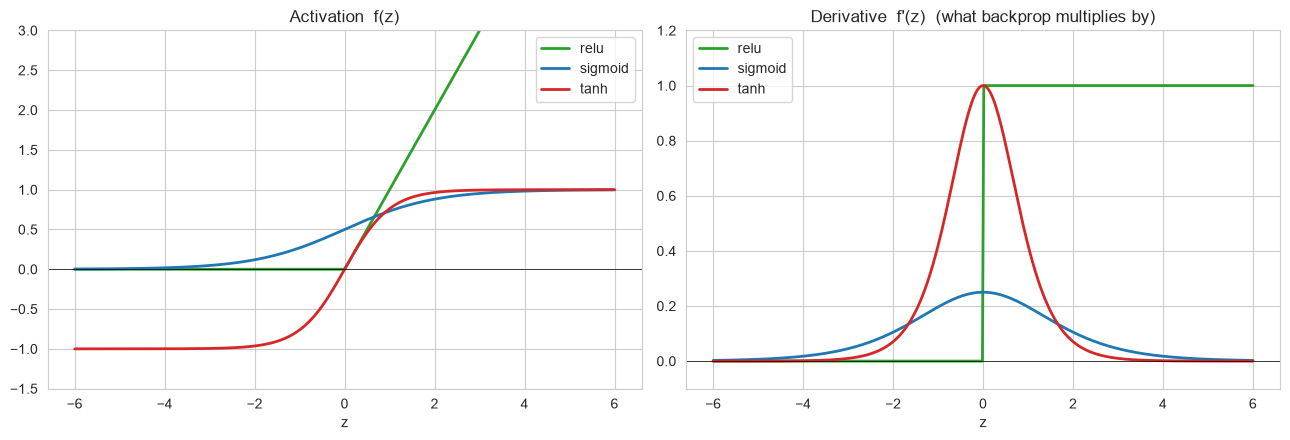

In [10]:
def relu(z):         return np.maximum(0, z)
def relu_grad(z):    return (z > 0).astype(z.dtype)

def sigmoid(z):      return 0.5 * (1 + np.tanh(0.5 * z))        # numerically stable form of 1/(1+e^-z)
def sigmoid_grad(z):
    s = sigmoid(z)
    return s * (1 - s)

def tanh(z):         return np.tanh(z)
def tanh_grad(z):    return 1 - np.tanh(z) ** 2

ACTIVATIONS = {
    "relu": (relu, relu_grad),
    "sigmoid": (sigmoid, sigmoid_grad),
    "tanh": (tanh, tanh_grad),
}

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)                        # subtract max for stability
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

z = np.linspace(-6, 6, 400)
colors = {"relu": "tab:green", "sigmoid": "tab:blue", "tanh": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (f, g) in ACTIVATIONS.items():
    axes[0].plot(z, f(z), label=name, color=colors[name], lw=2)
    axes[1].plot(z, g(z), label=name, color=colors[name], lw=2)
axes[0].set_title("Activation  f(z)"); axes[1].set_title("Derivative  f'(z)  (what backprop multiplies by)")
axes[0].set_ylim(-1.5, 3); axes[1].set_ylim(-0.1, 1.2)
for ax in axes:
    ax.set_xlabel("z"); ax.legend(); ax.axhline(0, color="k", lw=0.5)
plt.tight_layout()
plt.show()

** Sigmoid and Tanh *saturate*: for large |z| the curve is flat, so the derivative is almost 0 and learning signals fade. Sigmoid's derivative never exceeds 0.25; Tanh peaks at 1 and is centred on 0. ReLU has a constant derivative of 1 for positive inputs but is exactly 0 for negative ones (a unit that always receives negative input stops learning, the "dying ReLU" problem).

## 3.4 Forward propagation, loss and backpropagation
For a network with layers `l = 1 ... L`:

**Forward propagation** (batch `A0 = X`, shape `n x features`)
$$Z_l = A_{l-1}W_l + b_l,\qquad A_l = f(Z_l)\ \text{for hidden layers},\qquad A_L = \text{softmax}(Z_L)$$

**Loss** (cross-entropy over `n` samples, plus optional L2 penalty)
$$\mathcal{L} = -\frac1n\sum_i \log \hat p_{i,y_i} + \frac{\lambda}{2}\sum_l \lVert W_l\rVert^2$$

**Backpropagation** (chain rule, from output to input)
$$dZ_L = \frac{\hat P - Y_{onehot}}{n},\quad dW_l = A_{l-1}^\top dZ_l + \lambda W_l,\quad db_l = \sum dZ_l,\quad dZ_{l-1} = (dZ_l W_l^\top)\odot f'(Z_{l-1})$$

The `softmax + cross-entropy` pair gives the very simple output gradient `P - Y`.

**Weight initialization** matters: weights that are too small make signals vanish, too large make them explode. We use **He** init (std = sqrt(2 / fan_in)) for ReLU and **Xavier** (std = sqrt(1 / fan_in)) for Sigmoid/Tanh.

In [11]:
class MLP:
    """Fully connected network: hidden layers use `activation`, output layer is softmax."""

    def __init__(self, layer_sizes, activation="relu", init="auto", l2=0.0, seed=0, dtype=np.float32):
        self.sizes, self.activation, self.l2, self.dtype = list(layer_sizes), activation, l2, dtype
        self.act, self.act_grad = ACTIVATIONS[activation]
        r = np.random.default_rng(seed)
        if init == "auto":
            init = "he" if activation == "relu" else "xavier"
        self.W, self.b = [], []
        for n_in, n_out in zip(self.sizes[:-1], self.sizes[1:]):
            std = {"he": np.sqrt(2.0 / n_in), "xavier": np.sqrt(1.0 / n_in), "small": 0.01}[init]
            self.W.append((r.normal(0, std, (n_in, n_out))).astype(dtype))
            self.b.append(np.zeros(n_out, dtype=dtype))
        self.params = self.W + self.b            # same arrays, so in-place updates are shared

    def forward(self, X):
        self.A, self.Z = [X.astype(self.dtype, copy=False)], []
        for l in range(len(self.W)):
            z = self.A[-1] @ self.W[l] + self.b[l]
            self.Z.append(z)
            self.A.append(softmax(z) if l == len(self.W) - 1 else self.act(z))
        return self.A[-1]                          # class probabilities

    def loss(self, probs, y, with_reg=True):
        nll = -np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1.0)).mean()
        if with_reg and self.l2:
            nll += 0.5 * self.l2 * sum((W.astype(np.float64) ** 2).sum() for W in self.W)
        return float(nll)

    def backward(self, y):
        n, L = len(y), len(self.W)
        dZ = self.A[-1].copy()
        dZ[np.arange(n), y] -= 1.0
        dZ /= n                                    # dL/dZ_L = (P - Y) / n
        gW, gb = [None] * L, [None] * L
        for l in reversed(range(L)):
            gW[l] = self.A[l].T @ dZ + self.l2 * self.W[l]
            gb[l] = dZ.sum(axis=0)
            if l > 0:
                dZ = (dZ @ self.W[l].T) * self.act_grad(self.Z[l - 1])
        return gW + gb                             # same order as self.params

    def predict(self, X, batch=2048):
        return np.concatenate([self.forward(X[i:i + batch]).argmax(1) for i in range(0, len(X), batch)])

    def n_params(self):
        return int(sum(p.size for p in self.params))

### Trace one forward and backward pass
A tiny network (4 inputs, two hidden layers, 3 classes) on 5 samples, to see the shapes and the loss before any training.

In [12]:
demo = MLP([4, 6, 5, 3], activation="relu", seed=1)
Xd = np.random.default_rng(1).normal(size=(5, 4)).astype(np.float32)
yd = np.array([0, 1, 2, 1, 0])

probs = demo.forward(Xd)
print("Forward pass")
for l, (z, a) in enumerate(zip(demo.Z, demo.A[1:]), 1):
    kind = "softmax" if l == len(demo.Z) else demo.activation
    print(f"  layer {l}: Z {z.shape} -> A {a.shape}  ({kind})")
print("\nPredicted probabilities (each row sums to 1):\n", probs.round(3))
print(f"\nCross-entropy loss: {demo.loss(probs, yd):.4f}   (random guessing for 3 classes = ln 3 = {np.log(3):.4f})")

grads = demo.backward(yd)
print("\nBackward pass: gradient shapes match the parameters")
for name, p, g in zip([f"W{i}" for i in range(1, 4)] + [f"b{i}" for i in range(1, 4)], demo.params, grads):
    print(f"  {name}: param {p.shape}  grad {g.shape}")

Forward pass
  layer 1: Z (5, 6) -> A (5, 6)  (relu)
  layer 2: Z (5, 5) -> A (5, 5)  (relu)
  layer 3: Z (5, 3) -> A (5, 3)  (softmax)

Predicted probabilities (each row sums to 1):
 [[0.439 0.404 0.157]
 [0.674 0.147 0.179]
 [0.479 0.236 0.286]
 [0.342 0.306 0.352]
 [0.346 0.364 0.29 ]]

Cross-entropy loss: 1.2484   (random guessing for 3 classes = ln 3 = 1.0986)

Backward pass: gradient shapes match the parameters
  W1: param (4, 6)  grad (4, 6)
  W2: param (6, 5)  grad (6, 5)
  W3: param (5, 3)  grad (5, 3)
  b1: param (6,)  grad (6,)
  b2: param (5,)  grad (5,)
  b3: param (3,)  grad (3,)


### Gradient check: is our backpropagation correct?
We compare the analytic gradient with a numerical estimate `(L(w + e) - L(w - e)) / 2e`. If backprop is implemented correctly, the relative difference is tiny (about 1e-7 or smaller in double precision).

In [13]:
def numerical_grads(model, X, y, eps=1e-5):
    out = []
    for p in model.params:
        g = np.zeros_like(p)
        for idx in np.ndindex(*p.shape):
            old = p[idx]
            p[idx] = old + eps; lp = model.loss(model.forward(X), y)
            p[idx] = old - eps; lm = model.loss(model.forward(X), y)
            p[idx] = old
            g[idx] = (lp - lm) / (2 * eps)
        out.append(g)
    return out

r = np.random.default_rng(0)
Xc, yc = r.normal(size=(8, 5)), r.integers(0, 3, 8)
rows = []
for act in ACTIVATIONS:
    m = MLP([5, 4, 4, 3], activation=act, l2=0.01, seed=3, dtype=np.float64)    # float64 for precision
    m.forward(Xc)
    analytic = m.backward(yc)
    numeric = numerical_grads(m, Xc, yc)
    rel = max(np.max(np.abs(a - n) / np.maximum(np.abs(a) + np.abs(n), 1e-12)) for a, n in zip(analytic, numeric))
    rows.append({"activation": act, "max relative error": f"{rel:.2e}", "backprop correct": rel < 1e-5})
display(pd.DataFrame(rows))

,activation,max relative error,backprop correct
0,relu,1.82e-07,True
1,sigmoid,1.03e-07,True
2,tanh,7.68e-09,True


## 3.5 Training loop and experiments with activations
We need three more pieces: **optimizers** (how weights are updated from gradients), a **training loop** (mini-batches, evaluation each epoch) and optional learning-rate decay and early stopping.

| Optimizer | Update idea |
|---|---|
| SGD | `w -= lr * g` |
| SGD + momentum | keep a running velocity: `v = beta*v - lr*g; w += v` |
| RMSprop | divide the step by a running RMS of recent gradients, so each weight gets its own step size |
| Adam | momentum **and** RMSprop-style scaling, with bias correction |

In [14]:
class SGD:
    def __init__(self, lr=0.01, momentum=0.0):
        self.lr, self.momentum, self.v = lr, momentum, None
    def step(self, params, grads):
        if self.v is None:
            self.v = [np.zeros_like(p) for p in params]
        for p, g, v in zip(params, grads, self.v):
            v *= self.momentum
            v -= self.lr * g
            p += v

class RMSprop:
    def __init__(self, lr=1e-3, rho=0.9, eps=1e-8):
        self.lr, self.rho, self.eps, self.s = lr, rho, eps, None
    def step(self, params, grads):
        if self.s is None:
            self.s = [np.zeros_like(p) for p in params]
        for p, g, s in zip(params, grads, self.s):
            s *= self.rho
            s += (1 - self.rho) * g * g
            p -= self.lr * g / (np.sqrt(s) + self.eps)

class Adam:
    def __init__(self, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, beta1, beta2, eps
        self.m = self.v = None
        self.t = 0
    def step(self, params, grads):
        if self.m is None:
            self.m = [np.zeros_like(p) for p in params]
            self.v = [np.zeros_like(p) for p in params]
        self.t += 1
        c1, c2 = 1 - self.b1 ** self.t, 1 - self.b2 ** self.t          # bias correction
        for p, g, m, v in zip(params, grads, self.m, self.v):
            m *= self.b1; m += (1 - self.b1) * g
            v *= self.b2; v += (1 - self.b2) * g * g
            p -= self.lr * (m / c1) / (np.sqrt(v / c2) + self.eps)

In [15]:
def evaluate(model, X, y, batch=2048):
    probs = np.concatenate([model.forward(X[i:i + batch]) for i in range(0, len(X), batch)])
    return model.loss(probs, y, with_reg=False), float((probs.argmax(1) == y).mean())

def train(model, opt, Xtr, ytr, Xva, yva, epochs=25, batch_size=64, lr_decay=1.0,
          patience=None, seed=0, verbose=False):
    """Mini-batch training. lr_decay multiplies the learning rate each epoch.
    With `patience`, stop when validation loss has not improved for that many epochs and
    restore the best weights."""
    r = np.random.default_rng(seed)
    lr0 = opt.lr
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "lr"]}
    best_loss, best_state, wait = np.inf, None, 0
    t0 = time.time()
    with np.errstate(all="ignore"):                       # a diverging run should not spam warnings
        for ep in range(epochs):
            opt.lr = lr0 * lr_decay ** ep
            order = r.permutation(len(ytr))
            for s in range(0, len(order), batch_size):
                b = order[s:s + batch_size]
                model.forward(Xtr[b])
                opt.step(model.params, model.backward(ytr[b]))
            tl, ta = evaluate(model, Xtr, ytr)
            vl, va = evaluate(model, Xva, yva)
            for k, v in zip(hist, [tl, vl, ta, va, opt.lr]):
                hist[k].append(v)
            if verbose:
                print(f"epoch {ep + 1:3d} | train loss {tl:.4f} acc {ta:.3f} | val loss {vl:.4f} acc {va:.3f}")
            if not np.isfinite(tl):
                print("  (training diverged: loss is not finite)")
                break
            if patience:
                if vl < best_loss - 1e-4:
                    best_loss, best_state, wait = vl, [p.copy() for p in model.params], 0
                else:
                    wait += 1
                    if wait >= patience:
                        break
    if patience and best_state is not None:
        for p, s in zip(model.params, best_state):
            p[...] = s
        hist["best_epoch"] = int(np.argmin(hist["val_loss"])) + 1
    hist["time"] = time.time() - t0
    opt.lr = lr0
    return hist

### Experiment A: activations on a non-linear toy problem
Three interleaved spirals cannot be separated by any straight line, so they are a good test of what hidden layers and activations can do. The data is 2-D, so we can *see* the decision boundary each network learns.

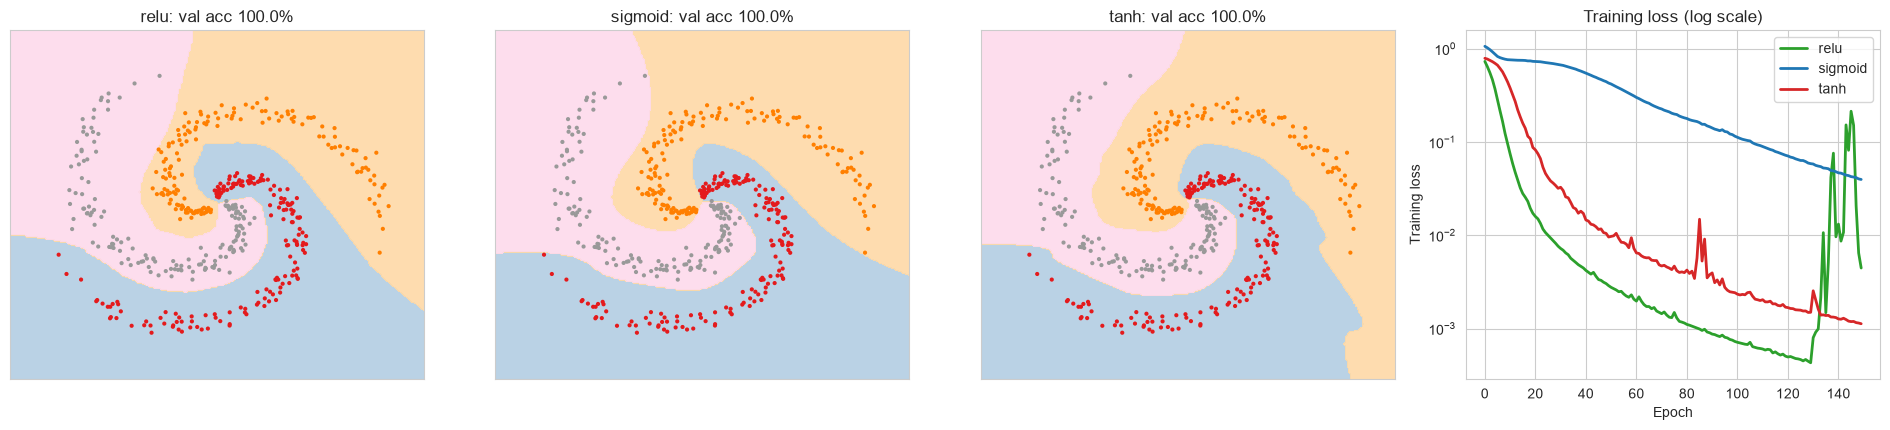

,activation,final train loss,final val loss,train acc,val acc,seconds
0,relu,0.0045,0.0010,0.9979,1.0,0.5183
1,sigmoid,0.0397,0.0225,0.9979,1.0,0.6156
2,tanh,0.0011,0.0005,1.0000,1.0,0.5707


In [16]:
def make_spiral(n=200, k=3, noise=0.2, rng=rng):
    X, y = [], []
    for j in range(k):
        radius = np.linspace(0.05, 1, n)
        theta = np.linspace(j * 4, (j + 1) * 4, n) + rng.normal(0, noise, n)
        X.append(np.c_[radius * np.sin(theta), radius * np.cos(theta)])
        y.append(np.full(n, j))
    X, y = np.concatenate(X).astype(np.float32), np.concatenate(y)
    p = rng.permutation(len(y))
    return X[p], y[p]

Xs, ys = make_spiral()
cut = int(0.8 * len(ys))
Xs_tr, ys_tr, Xs_va, ys_va = Xs[:cut], ys[:cut], Xs[cut:], ys[cut:]

gx, gy = np.meshgrid(np.linspace(-1.2, 1.2, 250), np.linspace(-1.2, 1.2, 250))
grid = np.c_[gx.ravel(), gy.ravel()].astype(np.float32)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))
curves, rows = {}, []
for ax, act in zip(axes[:3], ACTIVATIONS):
    net = MLP([2, 32, 32, 3], activation=act, seed=0)
    h = train(net, Adam(lr=0.01), Xs_tr, ys_tr, Xs_va, ys_va, epochs=150, batch_size=64)
    curves[act] = h
    ax.contourf(gx, gy, net.predict(grid).reshape(gx.shape), levels=[-0.5, 0.5, 1.5, 2.5], cmap="Pastel1", alpha=0.9)
    ax.scatter(Xs_tr[:, 0], Xs_tr[:, 1], c=ys_tr, cmap="Set1", s=9, edgecolor="none")
    ax.set_title(f"{act}: val acc {h['val_acc'][-1]:.1%}")
    ax.set_xticks([]); ax.set_yticks([])
    rows.append({"activation": act, "final train loss": h["train_loss"][-1], "final val loss": h["val_loss"][-1],
                 "train acc": h["train_acc"][-1], "val acc": h["val_acc"][-1], "seconds": h["time"]})
for act, h in curves.items():
    axes[3].plot(h["train_loss"], label=act, color=colors[act], lw=2)
axes[3].set_yscale("log"); axes[3].set_xlabel("Epoch"); axes[3].set_ylabel("Training loss"); axes[3].legend()
axes[3].set_title("Training loss (log scale)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(4))

**Conclude:** compare how smoothly each network bends its boundary around the spiral arms and how quickly the loss falls. 
Same architecture, same optimizer and same seed, so differences come from the activation alone.

### Experiment B: vanishing gradients in a deep network
We build a deep network (8 hidden layers of 64 units) and measure the size of the gradient reaching each layer after one backward pass. If gradients shrink toward the early layers, those layers barely learn.

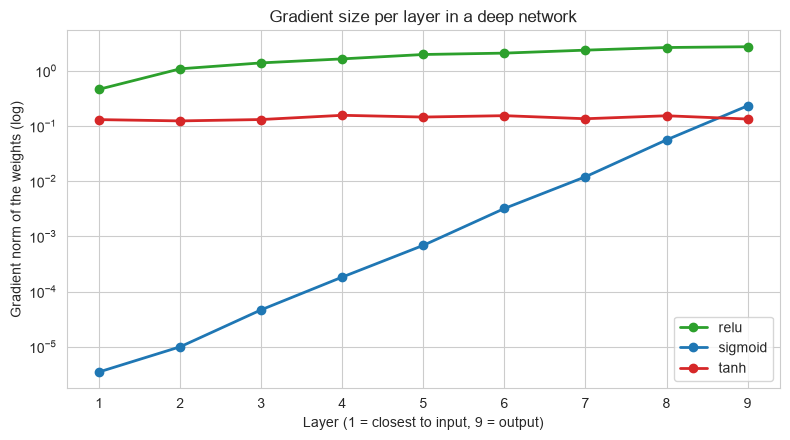

In [17]:
depth = 8
deep_sizes = [64] + [64] * depth + [4]
Xr = rng.normal(size=(256, 64)).astype(np.float32)
yr = rng.integers(0, 4, 256)

plt.figure(figsize=(8, 4.5))
for act in ACTIVATIONS:
    m = MLP(deep_sizes, activation=act, seed=0)
    m.forward(Xr)
    grads = m.backward(yr)
    norms = [np.linalg.norm(g) for g in grads[:len(m.W)]]          # weight gradients, layer 1 .. output
    plt.plot(range(1, len(norms) + 1), norms, marker="o", label=act, color=colors[act], lw=2)
plt.yscale("log")
plt.xlabel("Layer (1 = closest to input, 9 = output)")
plt.ylabel("Gradient norm of the weights (log)")
plt.title("Gradient size per layer in a deep network")
plt.legend(); plt.tight_layout(); plt.show()

**Figure out:** with Sigmoid the gradient shrinks by a large factor at every layer going backwards (each layer multiplies by a derivative of at 
most 0.25), so the first layers see tiny signals. ReLU with He initialization and Tanh with Xavier keep the signal much healthier. This is a major 
reason ReLU became the default for deep networks.

### Experiment C: activations on the OCT data
Same recipe on the real task: 1,024 pixels, two hidden layers (128, 64), four output classes, Adam, 25 epochs.

relu     | train acc 0.966 | val acc 0.479 | 3.1s
sigmoid  | train acc 0.782 | val acc 0.421 | 8.0s
tanh     | train acc 0.981 | val acc 0.481 | 7.9s
Parameters per network: 139716


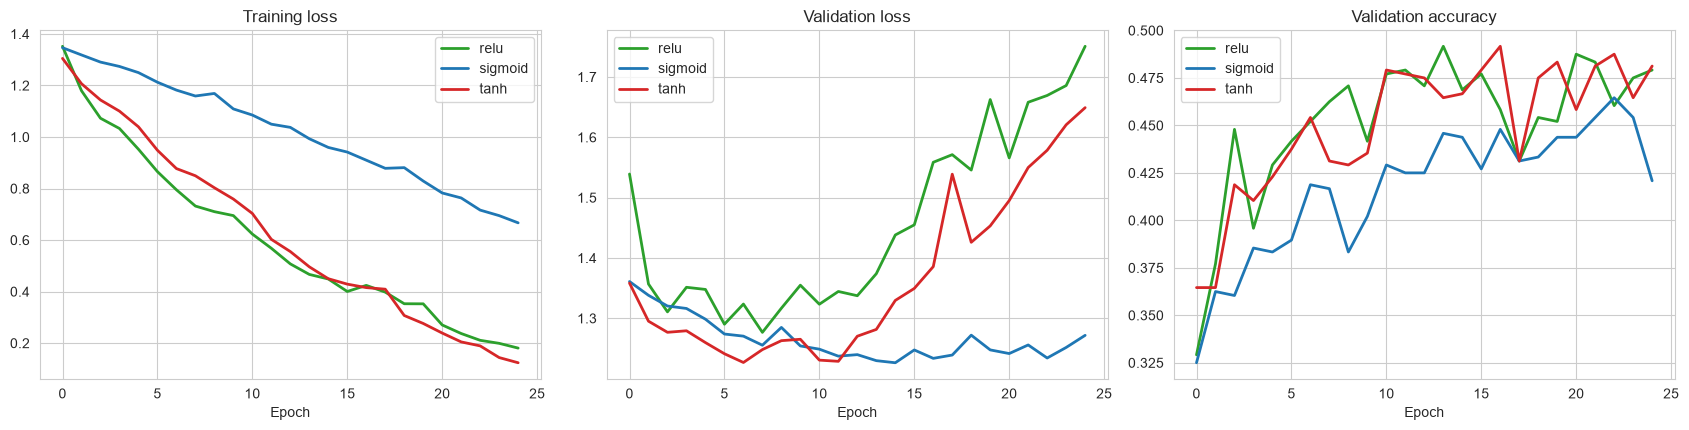

In [18]:
ARCH = [IMG * IMG, 128, 64, n_classes]
EPOCHS = 25
act_results = {}
for act in ACTIVATIONS:
    net = MLP(ARCH, activation=act, seed=0)
    act_results[act] = train(net, Adam(lr=1e-3), X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=64)
    h = act_results[act]
    print(f"{act:8s} | train acc {h['train_acc'][-1]:.3f} | val acc {h['val_acc'][-1]:.3f} | {h['time']:.1f}s")
print("Parameters per network:", net.n_params())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for act, h in act_results.items():
    axes[0].plot(h["train_loss"], color=colors[act], lw=2, label=act)
    axes[1].plot(h["val_loss"], color=colors[act], lw=2, label=act)
    axes[2].plot(h["val_acc"], color=colors[act], lw=2, label=act)
axes[0].set_title("Training loss"); axes[1].set_title("Validation loss"); axes[2].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.show()

**Look:** the gap between training loss and validation loss. A network that keeps lowering training loss while validation loss turns upward is 
**overfitting** (memorizing 1,920 training scans instead of learning general patterns). Section 3.6 shows tools to manage this. 
Random-guess accuracy for four balanced classes is 25%.

## 3.6 Optimization techniques: how does the model learn?
All runs below use the same ReLU network, data and seed, so only the setting being studied changes.

### 3.6.1 Optimizers

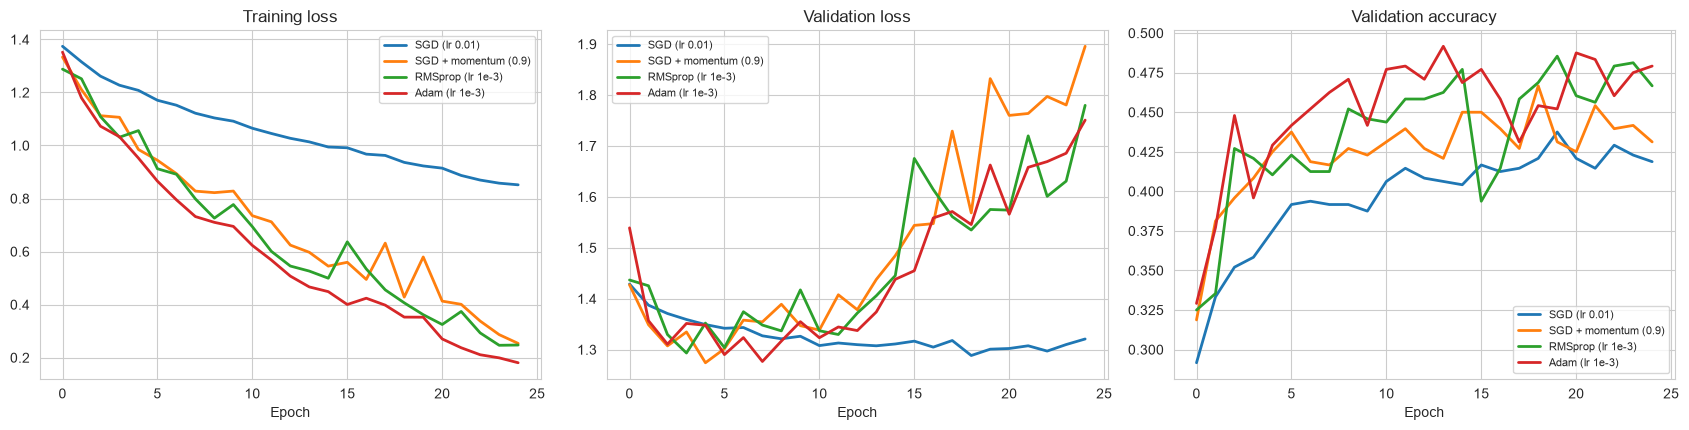

,optimizer,best val acc,epoch of best val loss,final train loss
0,SGD (lr 0.01),0.4375,19,0.8517
1,SGD + momentum (0.9),0.4667,5,0.2536
2,RMSprop (lr 1e-3),0.4854,4,0.2475
3,Adam (lr 1e-3),0.4917,8,0.1806


In [19]:
def fresh_net(**kw):
    return MLP(ARCH, activation=kw.pop("activation", "relu"), seed=0, **kw)

optimizers = {
    "SGD (lr 0.01)":               lambda: SGD(lr=0.01),
    "SGD + momentum (0.9)":        lambda: SGD(lr=0.01, momentum=0.9),
    "RMSprop (lr 1e-3)":           lambda: RMSprop(lr=1e-3),
    "Adam (lr 1e-3)":              lambda: Adam(lr=1e-3),
}
opt_results = {name: train(fresh_net(), make(), X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=64)
               for name, make in optimizers.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for name, h in opt_results.items():
    axes[0].plot(h["train_loss"], lw=2, label=name)
    axes[1].plot(h["val_loss"], lw=2, label=name)
    axes[2].plot(h["val_acc"], lw=2, label=name)
axes[0].set_title("Training loss"); axes[1].set_title("Validation loss"); axes[2].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

display(pd.DataFrame([{"optimizer": n, "best val acc": max(h["val_acc"]), "epoch of best val loss": int(np.argmin(h["val_loss"])) + 1,
                       "final train loss": h["train_loss"][-1]} for n, h in opt_results.items()]).round(4))

** look for:** plain SGD follows the raw gradient and is slow when gradients are small or the loss surface is uneven. Momentum smooths and accelerates
the path; RMSprop and Adam adapt the step size per weight, which usually makes them converge fastest with little tuning.

### 3.6.2 Learning rate
The learning rate is usually the single most important hyperparameter. Too small and learning crawls; too large and the loss bounces or blows up.

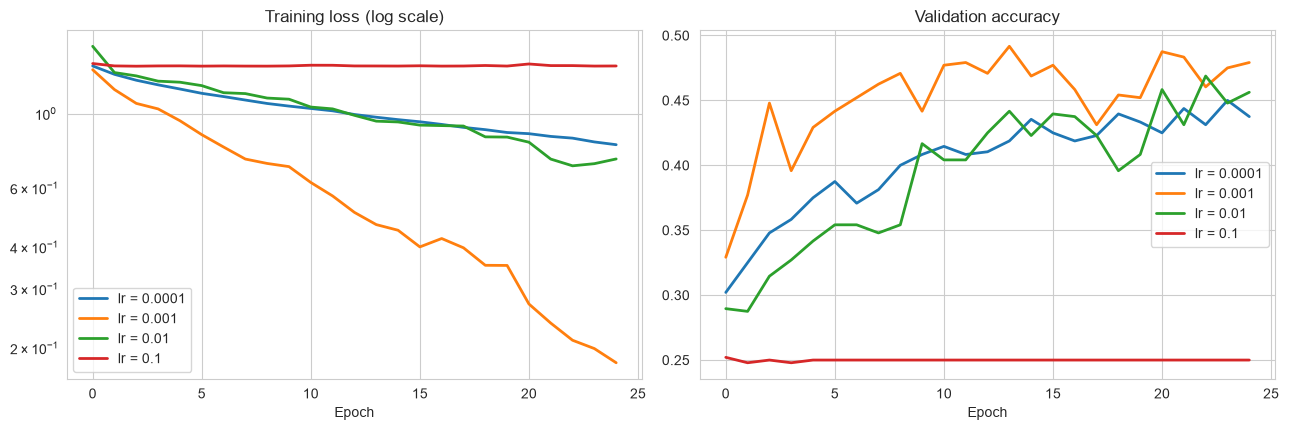

In [20]:
lrs = [1e-4, 1e-3, 1e-2, 1e-1]
lr_results = {lr: train(fresh_net(), Adam(lr=lr), X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=64) for lr in lrs}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for lr, h in lr_results.items():
    axes[0].plot(h["train_loss"], lw=2, label=f"lr = {lr:g}")
    axes[1].plot(h["val_acc"], lw=2, label=f"lr = {lr:g}")
axes[0].set_yscale("log"); axes[0].set_title("Training loss (log scale)"); axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.show()

**look for:** the smallest rate descends slowly and steadily; moderate rates converge quickly; the largest rate is noisy and may overshoot or fail 
to settle. The sweet spot sits between "too slow" and "unstable".

### 3.6.3 Batch size
Smaller batches give noisier gradients but many more updates per epoch; larger batches give smoother gradients but fewer updates. The last option below is **full-batch** gradient descent.

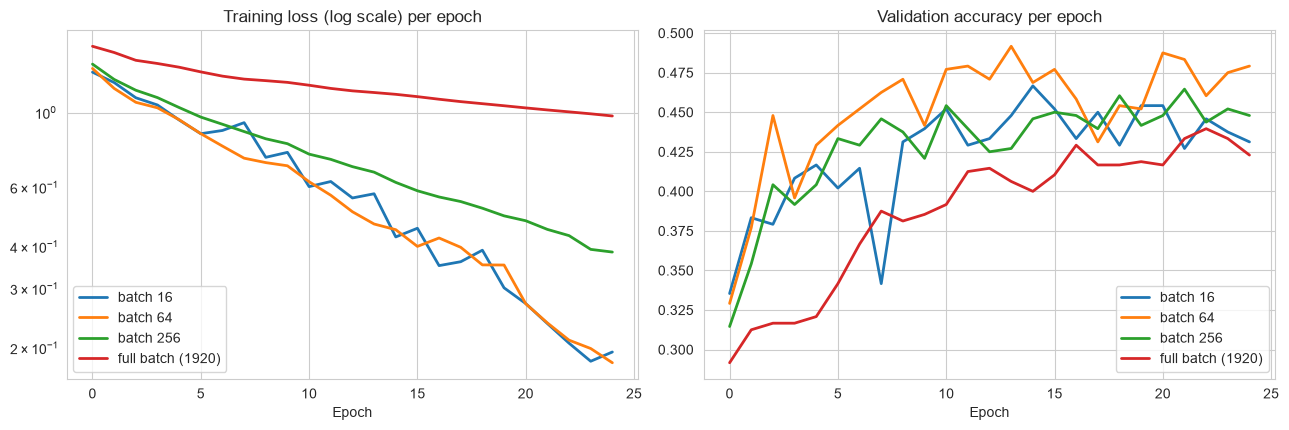

,batch size,updates per epoch,seconds,best val acc
0,16,120,14.7239,0.4667
1,64,30,7.1638,0.4917
2,256,8,4.0091,0.4646
3,1920,1,1.9794,0.4396


In [21]:
batch_sizes = [16, 64, 256, len(y_train)]
bs_results = {bs: train(fresh_net(), Adam(lr=1e-3), X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=bs) for bs in batch_sizes}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for bs, h in bs_results.items():
    label = f"batch {bs}" if bs != len(y_train) else f"full batch ({bs})"
    axes[0].plot(h["train_loss"], lw=2, label=label)
    axes[1].plot(h["val_acc"], lw=2, label=label)
axes[0].set_yscale("log"); axes[0].set_title("Training loss (log scale) per epoch"); axes[1].set_title("Validation accuracy per epoch")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame([{"batch size": bs, "updates per epoch": int(np.ceil(len(y_train) / bs)), "seconds": h["time"],
                       "best val acc": max(h["val_acc"])} for bs, h in bs_results.items()]).round(4))

**Final:** per *epoch*, small batches learn more (more weight updates). Per *second*, the picture can differ because large batches use the CPU more 
efficiently. Batch size 32-128 is a common compromise.

### 3.6.4 Regularization, learning-rate decay and early stopping
Overfitting is the main enemy with ~2,000 training images. Three remedies:
- **L2 weight penalty** (`lambda`) discourages large weights.
- **Learning-rate decay** takes big steps early and fine steps later.
- **Early stopping** keeps the weights from the epoch with the lowest validation loss.

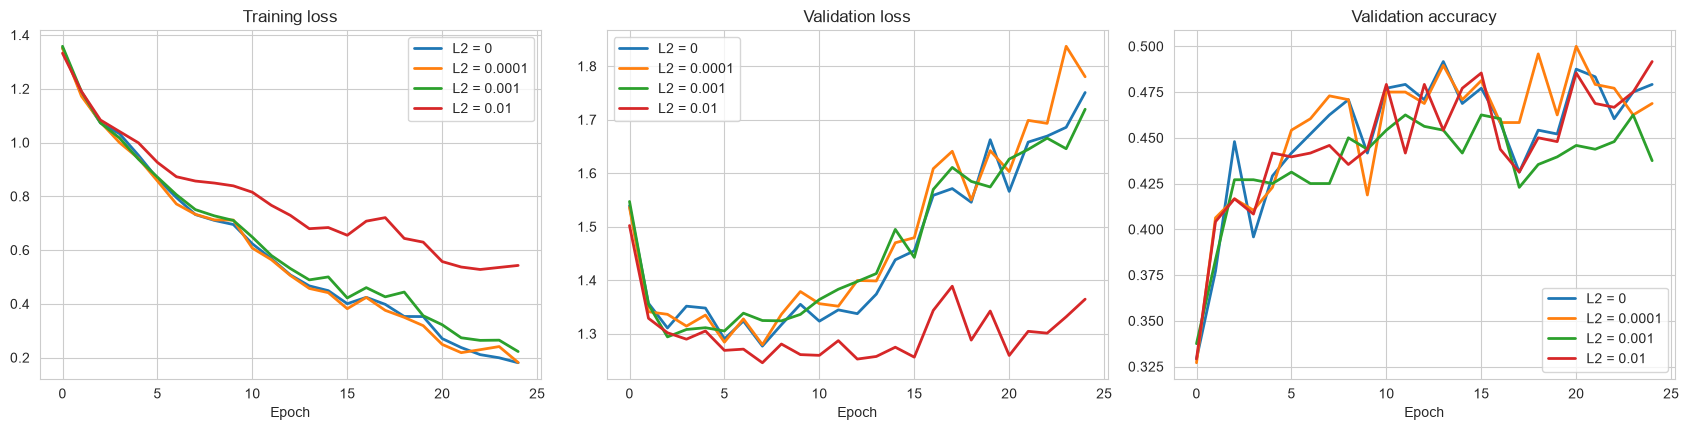

L2 value (> 0) with the lowest validation loss: 0.01


In [22]:
l2_values = [0.0, 1e-4, 1e-3, 1e-2]
l2_results = {l2: train(fresh_net(l2=l2), Adam(lr=1e-3), X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=64) for l2 in l2_values}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for l2, h in l2_results.items():
    axes[0].plot(h["train_loss"], lw=2, label=f"L2 = {l2:g}")
    axes[1].plot(h["val_loss"], lw=2, label=f"L2 = {l2:g}")
    axes[2].plot(h["val_acc"], lw=2, label=f"L2 = {l2:g}")
axes[0].set_title("Training loss"); axes[1].set_title("Validation loss"); axes[2].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.show()

best_l2 = min((k for k in l2_values if k > 0), key=lambda k: min(l2_results[k]["val_loss"]))
print("L2 value (> 0) with the lowest validation loss:", best_l2)

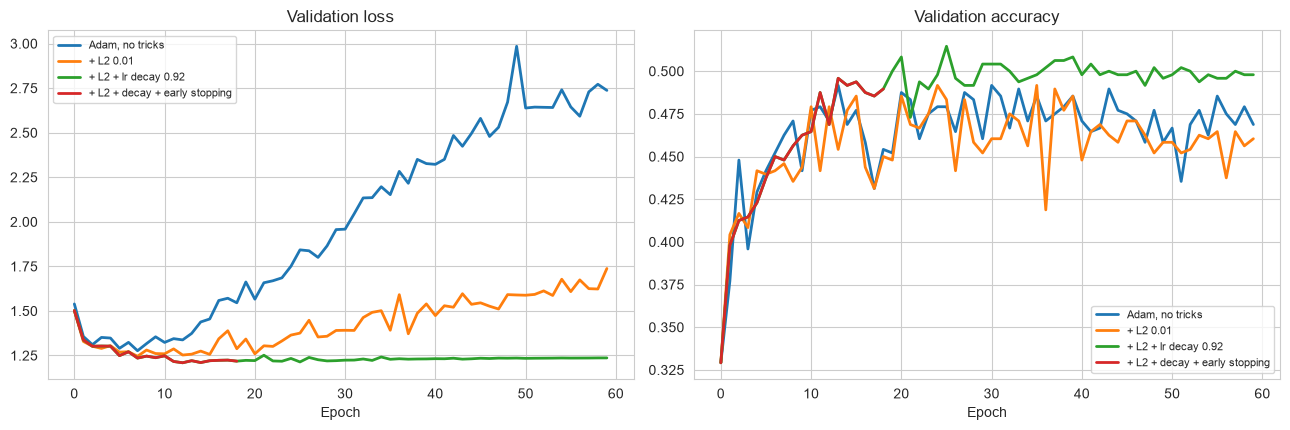

,setup,epochs run,best epoch,kept-weights val acc
0,"Adam, no tricks",60,8,0.4688
1,+ L2 0.01,60,8,0.4604
2,+ L2 + lr decay 0.92,60,13,0.4979
3,+ L2 + decay + early stopping,19,13,0.4688


In [23]:
# Learning-rate decay and early stopping, on top of the best L2 value
configs = {
    "Adam, no tricks":                   dict(l2=0.0,     lr_decay=1.0,  patience=None),
    f"+ L2 {best_l2:g}":                 dict(l2=best_l2, lr_decay=1.0,  patience=None),
    f"+ L2 + lr decay 0.92":             dict(l2=best_l2, lr_decay=0.92, patience=None),
    f"+ L2 + decay + early stopping":    dict(l2=best_l2, lr_decay=0.92, patience=6),
}
tune_results, tuned_models = {}, {}
for name, c in configs.items():
    net = fresh_net(l2=c["l2"])
    tune_results[name] = train(net, Adam(lr=1e-3), X_train, y_train, X_val, y_val, epochs=60, batch_size=64,
                               lr_decay=c["lr_decay"], patience=c["patience"])
    tuned_models[name] = net

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for name, h in tune_results.items():
    axes[0].plot(h["val_loss"], lw=2, label=name)
    axes[1].plot(h["val_acc"], lw=2, label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

rows = []
for name, h in tune_results.items():
    _, va = evaluate(tuned_models[name], X_val, y_val)               # accuracy of the weights we would actually keep
    rows.append({"setup": name, "epochs run": len(h["val_loss"]), "best epoch": h.get("best_epoch", int(np.argmin(h["val_loss"])) + 1),
                 "kept-weights val acc": va})
display(pd.DataFrame(rows).round(4))

**Final:** L2 and decay usually lower the validation loss and narrow the train/validation gap; early stopping prevents the validation loss from creeping back up. Neural networks need *regularized* training, not just *more* training.

## 3.7 Final model and test evaluation
We take the full recipe (Adam, best L2, lr decay, early stopping), judge it **once** on the untouched test split, and inspect what the first layer learned.

Final model: + L2 + decay + early stopping
  validation accuracy 0.469
  test accuracy       0.513   (loss 1.171)
  random guess        0.250


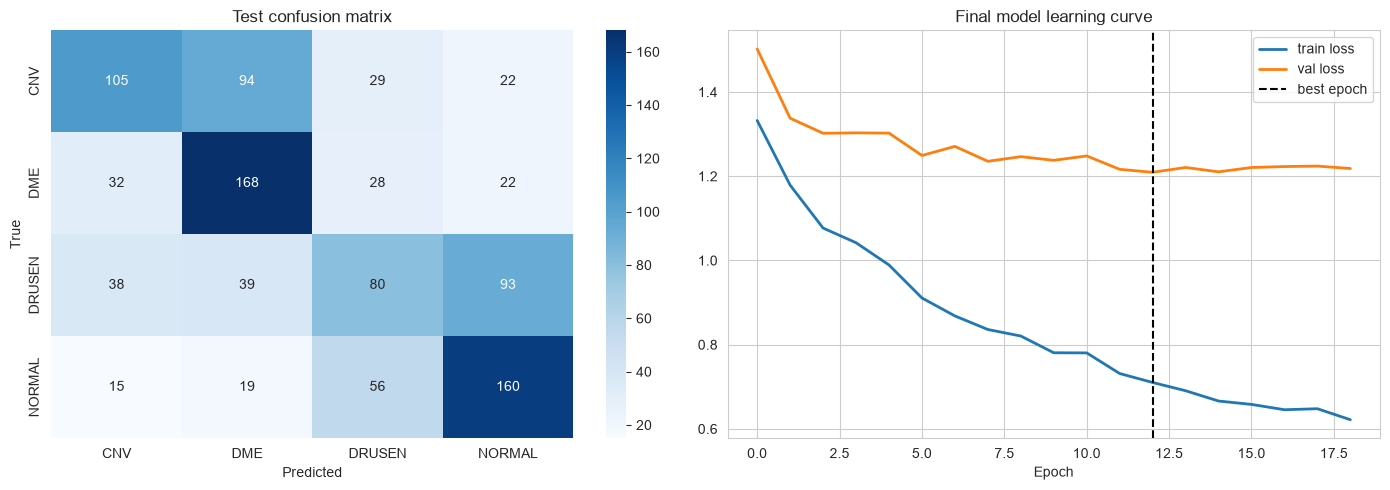

,class,recall,precision,test samples
0,CNV,0.420,0.553,250
1,DME,0.672,0.525,250
2,DRUSEN,0.320,0.415,250
3,NORMAL,0.640,0.539,250


In [24]:
final_name = list(configs)[-1]
final_net = tuned_models[final_name]
final_hist = tune_results[final_name]

test_loss, test_acc = evaluate(final_net, X_test, y_test)
val_loss, val_acc = evaluate(final_net, X_val, y_val)
print(f"Final model: {final_name}")
print(f"  validation accuracy {val_acc:.3f}")
print(f"  test accuracy       {test_acc:.3f}   (loss {test_loss:.3f})")
print(f"  random guess        {1 / n_classes:.3f}")

pred = final_net.predict(X_test)
cm = np.zeros((n_classes, n_classes), dtype=int)
np.add.at(cm, (y_test, pred), 1)
recall = cm.diagonal() / cm.sum(axis=1)
precision = cm.diagonal() / np.maximum(cm.sum(axis=0), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True"); axes[0].set_title("Test confusion matrix")
axes[1].plot(final_hist["train_loss"], label="train loss", lw=2)
axes[1].plot(final_hist["val_loss"], label="val loss", lw=2)
if "best_epoch" in final_hist:
    axes[1].axvline(final_hist["best_epoch"] - 1, color="k", ls="--", label="best epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_title("Final model learning curve"); axes[1].legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({"class": class_names, "recall": recall, "precision": precision, "test samples": cm.sum(axis=1)}).round(3))

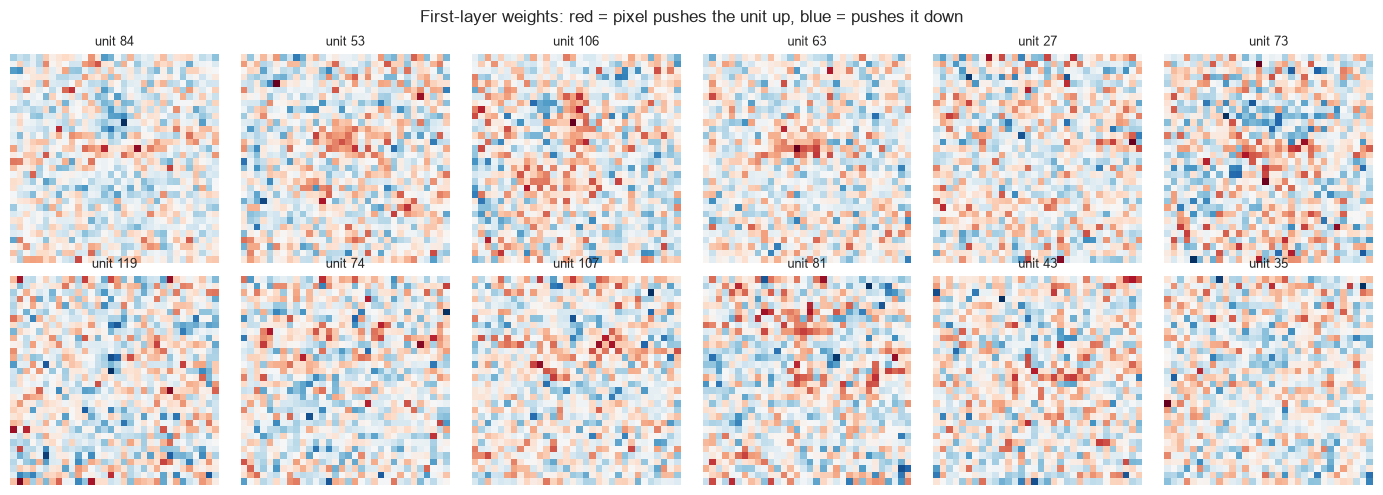

In [25]:
# What did the first layer learn? Each hidden unit is a 32x32 pattern of pixel weights.
W1 = final_net.W[0]
order = np.argsort(-np.linalg.norm(W1, axis=0))[:12]        # the 12 units with the largest weights
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, j in zip(axes.ravel(), order):
    w = W1[:, j].reshape(IMG, IMG)
    lim = np.abs(w).max()
    ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"unit {j}", fontsize=9)
    ax.axis("off")
plt.suptitle("First-layer weights: red = pixel pushes the unit up, blue = pushes it down", fontsize=12)
plt.tight_layout()
plt.show()

**What to look for:** the weights are not a clean "retina detector"; a fully connected network ignores pixel neighbourhoods and must learn the same pattern separately at every position. That limitation is exactly what **convolutional** layers fix in Step 4.

### Save the network and settings for later steps

In [26]:
np.savez("step3_mlp_weights.npz", **{f"W{i}": W for i, W in enumerate(final_net.W)}, **{f"b{i}": b for i, b in enumerate(final_net.b)})
config3 = {
    "input_size": IMG,
    "architecture": ARCH,
    "activation": final_net.activation,
    "optimizer": "Adam(lr=1e-3), lr decay 0.92, early stopping",
    "l2": final_net.l2,
    "pixel_mean": pix_mean,
    "pixel_std": pix_std,
    "val_accuracy": val_acc,
    "test_accuracy": test_acc,
    "class_names": class_names,
    "seed": SEED,
}
with open("nn_fundamentals_config.json", "w") as f:
    json.dump(config3, f, indent=2)
print("Saved step3_mlp_weights.npz and nn_fundamentals_config.json")

Saved step3_mlp_weights.npz and nn_fundamentals_config.json


## Summary of Step 3
- Built a **perceptron** from scratch; it solves AND/OR but not XOR, and cannot separate OCT classes from raw pixels.
- Implemented a full **multi-layer network in NumPy**: forward propagation, softmax cross-entropy loss, backpropagation, and verified the gradients numerically.
- Compared **ReLU, Sigmoid and Tanh** on a spiral problem, on vanishing gradients in a deep net, and on OCT data.
- Implemented **SGD, momentum, RMSprop and Adam** and studied learning rate, batch size, L2 regularization, learning-rate decay and early stopping.
- Evaluated the final network on the untouched test split.

**Key lessons to carry forward:** use ReLU with He initialization as the default, Adam as a safe optimizer, watch the train/validation gap, and keep the test set for one final check.

